# Projeto Prático 1 – Aproximação de Funções com Perceptron Multicamadas (PMC)

Este projeto visa estimar a energia absorvida em um sistema de ressonância magnética a partir de três grandezas ($x_1, x_2, x_3$) utilizando um PMC como aproximador universal.

## Configuração da Rede
- **Entradas:** 3 neurônios ($x_1, x_2, x_3$)
- **Camada Oculta:** 10 neurônios
- **Saída:** 1 neurônio ($y$)
- **Função de Ativação:** Logística (Sigmóide) em todas as camadas
- **Algoritmo:** Backpropagation convencional
- **Taxa de Aprendizado ($\eta$):** 0,1
- **Precisão ($\varepsilon$):** $10^{-6}$ (Erro Quadrático Médio)

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import io

%matplotlib inline

## 1. Carga e Preparação dos Dados

In [10]:
# Dados de Treinamento
train_df = pd.read_csv('datasets/projeto-pratico-1.csv')

# Dados de Teste (limpeza de aspas)
with open('datasets/conjunto-testes-projeto-pratico-1.csv', 'r') as f:
    lines = [line.replace('"', '').strip() for line in f.readlines()]
test_df = pd.read_csv(io.StringIO('\n'.join(lines)))

print("Treinamento:")
display(train_df.head())
print("\nTeste:")
display(test_df.head())

Treinamento:


,x1,x2,x3,d
0,0.8799,0.7998,0.3972,0.8399
1,0.5700,0.5111,0.2418,0.6258
2,0.6796,0.4117,0.3370,0.6622
3,0.3567,0.2967,0.6037,0.5969
4,0.3866,0.8390,0.0232,0.5316



Teste:


,Amostra,x1,x2,x3,d
0,1,0.0611,0.2860,0.7464,0.4831
1,2,0.5102,0.7464,0.0860,0.5965
2,3,0.0004,0.6916,0.5006,0.5318
3,4,0.9430,0.4476,0.2648,0.6843
4,5,0.1399,0.1610,0.2477,0.2872


## 2. Implementação do PMC

In [11]:
class MLPRegression:
    def __init__(self, input_size, hidden_size, output_size, seed=None):
        if seed is not None:
            np.random.seed(seed)
        
        # Pesos entre [-0.5, 0.5]
        self.W1 = np.random.uniform(-0.5, 0.5, (hidden_size, input_size + 1))
        self.W2 = np.random.uniform(-0.5, 0.5, (output_size, hidden_size + 1))

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def sigmoid_derivative(self, y):
        return y * (1 - y)

    def train(self, X, D, eta=0.1, epsilon=1e-6, max_epochs=5000):
        N = X.shape[0]
        mse_history = []
        
        for epoch in range(max_epochs):
            total_error = 0
            indices = np.random.permutation(N)
            
            for i in indices:
                x = X[i].reshape(-1, 1)
                d = D[i].reshape(-1, 1)
                
                # Forward
                x_bias = np.vstack([[-1], x])
                y1 = self.sigmoid(np.dot(self.W1, x_bias))
                
                y1_bias = np.vstack([[-1], y1])
                y2 = self.sigmoid(np.dot(self.W2, y1_bias))
                
                # Error
                e = d - y2
                total_error += (e**2).sum() * 0.5
                
                # Backward
                delta2 = e * self.sigmoid_derivative(y2)
                delta1 = self.sigmoid_derivative(y1) * np.dot(self.W2[:, 1:].T, delta2)
                
                # Update
                self.W2 += eta * np.dot(delta2, y1_bias.T)
                self.W1 += eta * np.dot(delta1, x_bias.T)
            
            mse = total_error / N
            mse_history.append(mse)
            
            if mse <= epsilon:
                break
                
        return mse_history, epoch + 1

    def predict(self, X):
        preds = []
        for i in range(X.shape[0]):
            x = X[i].reshape(-1, 1)
            x_bias = np.vstack([[-1], x])
            y1 = self.sigmoid(np.dot(self.W1, x_bias))
            y1_bias = np.vstack([[-1], y1])
            y2 = self.sigmoid(np.dot(self.W2, y1_bias))
            preds.append(y2.flatten()[0])
        return np.array(preds)

## 3. Execução dos 5 Treinamentos

In [13]:
X_train = train_df[['x1', 'x2', 'x3']].values
D_train = train_df[['d']].values

results = []
models = []
histories = []

for i in range(5):
    # Semente diferente para cada treinamento garante pesos iniciais distintos
    seed = np.random.randint(0, 10000)
    mlp = MLPRegression(3, 10, 1, seed=seed)
    history, epochs = mlp.train(X_train, D_train)
    
    models.append(mlp)
    histories.append(history)
    results.append({
        'Treinamento': f'T{i+1}',
        'Erro quadrático médio': history[-1],
        'Número total de épocas': epochs
    })

df_res = pd.DataFrame(results)
print("Tabela 5.2 – Resultados dos treinamentos")
display(df_res)

Tabela 5.2 – Resultados dos treinamentos


,Treinamento,Erro quadrático médio,Número total de épocas
0,T1,0.000105,5000
1,T2,0.000108,5000
2,T3,0.000104,5000
3,T4,0.000086,5000
4,T5,0.000098,5000


## 4. Gráficos dos Treinamentos Mais Longos

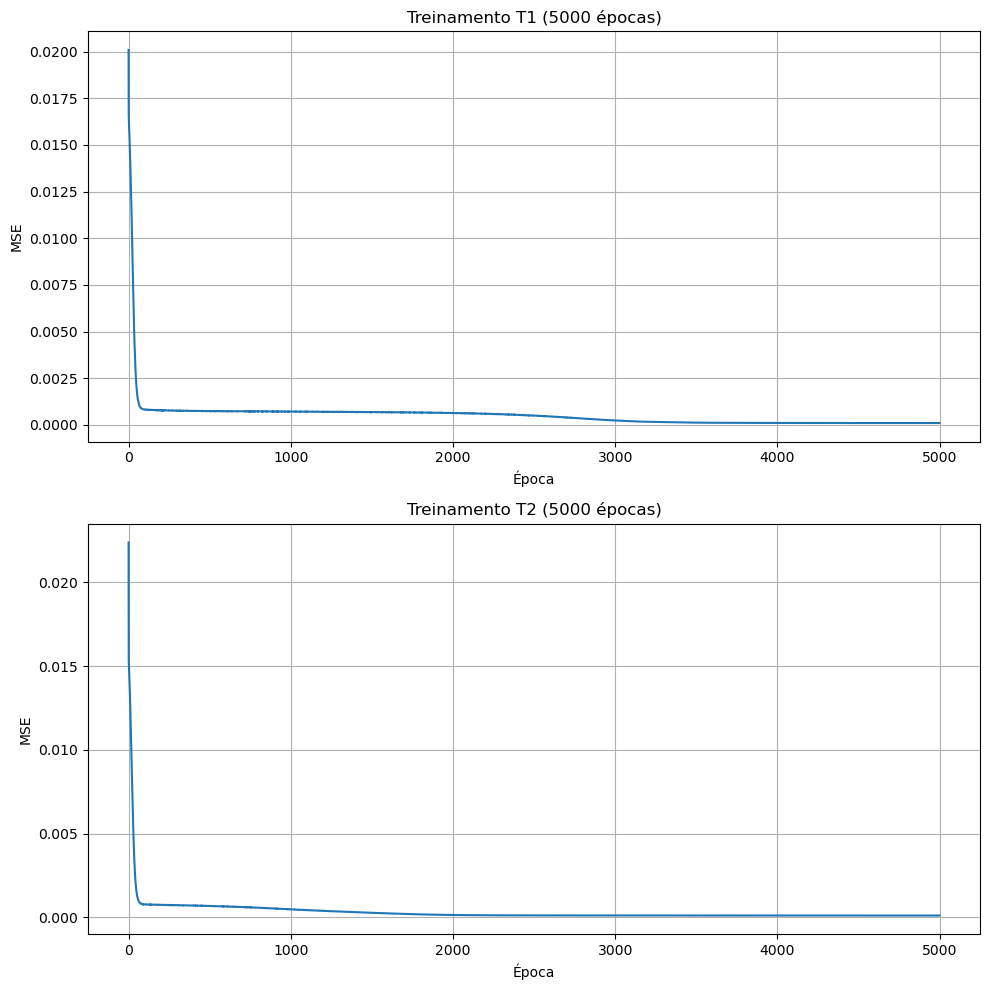

In [14]:
# Identificando os dois treinamentos com maior número de épocas
sorted_indices = df_res.sort_values(by='Número total de épocas', ascending=False).index[:2]

fig, axes = plt.subplots(2, 1, figsize=(10, 10))

for idx, ax in zip(sorted_indices, axes):
    ax.plot(histories[idx])
    ax.set_title(f"Treinamento {df_res.iloc[idx]['Treinamento']} ({df_res.iloc[idx]['Número total de épocas']} épocas)")
    ax.set_xlabel("Época")
    ax.set_ylabel("MSE")
    ax.grid(True)

plt.tight_layout()
plt.show()

## 4.1. Evolução do Erro Quadrático Médio (Melhor Treinamento Manual)

Abaixo, apresentamos a evolução do MSE para o treinamento que obteve o menor erro final entre as 5 execuções da implementação manual.

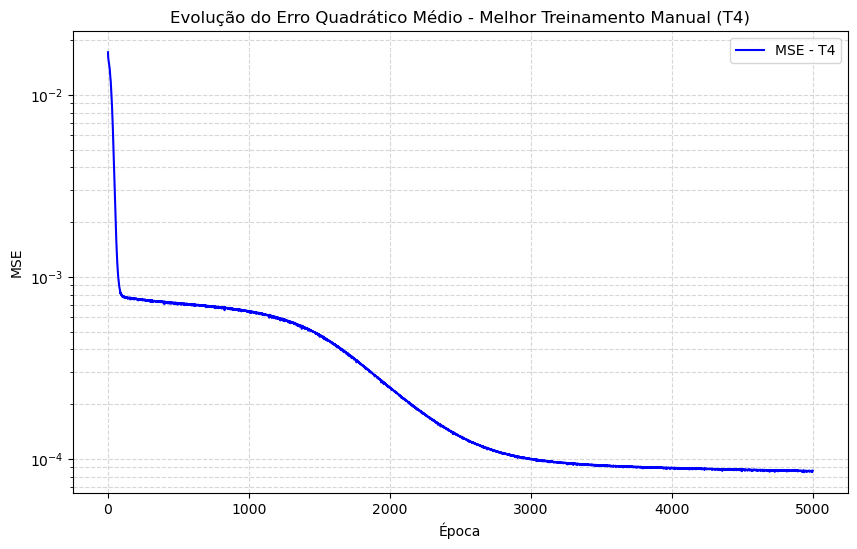

In [19]:
# Identificando o melhor treinamento manual (menor erro final)
best_manual_idx = df_res['Erro quadrático médio'].idxmin()
best_manual_name = df_res.loc[best_manual_idx, 'Treinamento']
best_manual_history = histories[best_manual_idx]

plt.figure(figsize=(10, 6))
plt.plot(best_manual_history, color='blue', label=f'MSE - {best_manual_name}')
plt.title(f'Evolução do Erro Quadrático Médio - Melhor Treinamento Manual ({best_manual_name})')
plt.xlabel('Época')
plt.ylabel('MSE')
plt.yscale('log') # Escala logarítmica facilita a visualização da convergência fina
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.show()

## 4.2. Evolução do Erro Quadrático Médio (Todos os 5 Treinamentos Manuais)

Abaixo, apresentamos a evolução do MSE para todos os 5 treinamentos realizados com a implementação manual, permitindo comparar a velocidade de convergência e o erro final de cada execução.

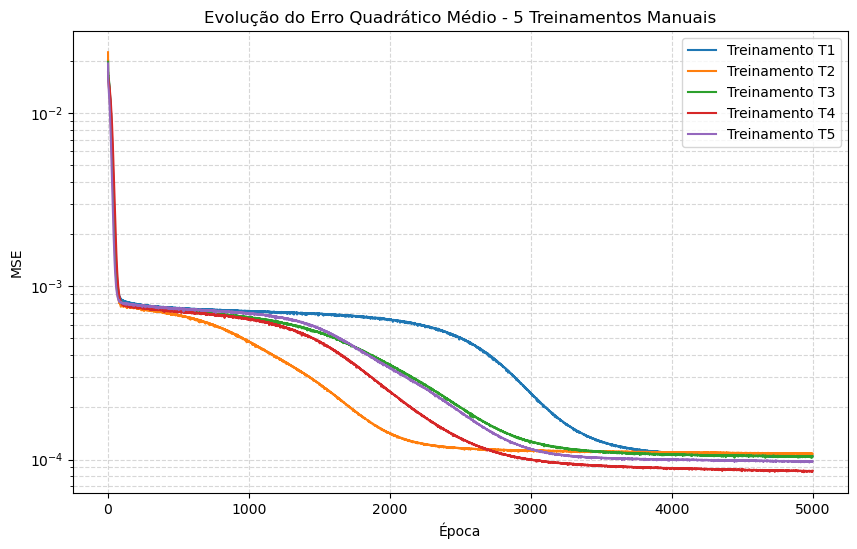

In [20]:
plt.figure(figsize=(10, 6))

for i, history in enumerate(histories):
    plt.plot(history, label=f'Treinamento T{i+1}')

plt.title('Evolução do Erro Quadrático Médio - 5 Treinamentos Manuais')
plt.xlabel('Época')
plt.ylabel('MSE')
plt.yscale('log')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.show()

## 5. Explicação da Variabilidade

A variabilidade nos resultados (MSE e número de épocas) ocorre principalmente devido à **inicialização aleatória dos pesos**. 

1. **Superfície de Erro:** O erro de uma rede neural define uma superfície não-convexa no espaço de pesos, repleta de mínimos locais, planos (plateaus) e pontos de sela.
2. **Ponto de Partida:** Pesos iniciais diferentes significam que o algoritmo de gradiente descendente inicia em pontos distintos dessa superfície. 
3. **Caminho de Otimização:** Dependendo de onde começa, a rede pode encontrar um caminho mais "íngreme" (convergência rápida) ou cair em regiões de gradiente quase nulo (muitas épocas para avançar).
4. **Mínimos Locais:** A rede pode convergir para mínimos locais diferentes, resultando em erros finais ligeiramente distintos, mesmo que todos atendam ao critério $\varepsilon$ ou ao limite de épocas.

## 6. Validação com Conjunto de Teste

In [15]:
X_test = test_df[['x1', 'x2', 'x3']].values
D_test = test_df['d'].values

val_results_summary = []
test_results_detailed = test_df.copy()

for i, mlp in enumerate(models):
    Y_pred = mlp.predict(X_test)
    t_name = f'y_T{i+1}'
    test_results_detailed[t_name] = Y_pred
    
    # Erro relativo: |d - y| / d
    rel_errors = np.abs(D_test - Y_pred) / D_test * 100
    
    val_results_summary.append({
        'Treinamento': f'T{i+1}',
        'Erro relativo médio (%)': np.mean(rel_errors),
        'Variância (%)': np.var(rel_errors)
    })

df_val = pd.DataFrame(val_results_summary)

print("Tabela Detalhada de Amostras e Predições (T1 a T5):")
display(test_results_detailed)

print("\nTabela 5.3 – Resumo das Métricas de Validação:")
display(df_val)

best_t = df_val.loc[df_val['Erro relativo médio (%)'].idxmin()]['Treinamento']
print(f"\nMelhor generalização: {best_t}")

Tabela Detalhada de Amostras e Predições (T1 a T5):


,Amostra,x1,x2,x3,d,y_T1,y_T2,y_T3,y_T4,y_T5
0,1,0.0611,0.2860,0.7464,0.4831,0.478718,0.468234,0.472590,0.474719,0.465594
1,2,0.5102,0.7464,0.0860,0.5965,0.589023,0.582348,0.581836,0.587989,0.584757
2,3,0.0004,0.6916,0.5006,0.5318,0.505914,0.510379,0.504918,0.509188,0.514809
3,4,0.9430,0.4476,0.2648,0.6843,0.697256,0.704225,0.702287,0.700287,0.698481
4,5,0.1399,0.1610,0.2477,0.2872,0.300224,0.297880,0.299160,0.297545,0.294873
5,6,0.6423,0.3229,0.8567,0.7663,0.773020,0.772057,0.773013,0.774435,0.775757
6,7,0.6492,0.0007,0.6422,0.5666,0.537840,0.540697,0.532390,0.539024,0.534507
7,8,0.1818,0.5078,0.9046,0.6601,0.666782,0.665632,0.666045,0.666517,0.663506
8,9,0.7382,0.2647,0.1916,0.5427,0.534628,0.545700,0.542081,0.536973,0.541215
9,10,0.3879,0.1307,0.8656,0.5836,0.574569,0.584113,0.581562,0.582343,0.590626



Tabela 5.3 – Resumo das Métricas de Validação:


,Treinamento,Erro relativo médio (%),Variância (%)
0,T1,1.856338,1.824975
1,T2,1.792764,1.588931
2,T3,1.882722,2.360817
3,T4,1.594249,1.607996
4,T5,1.737684,1.595497



Melhor generalização: T4


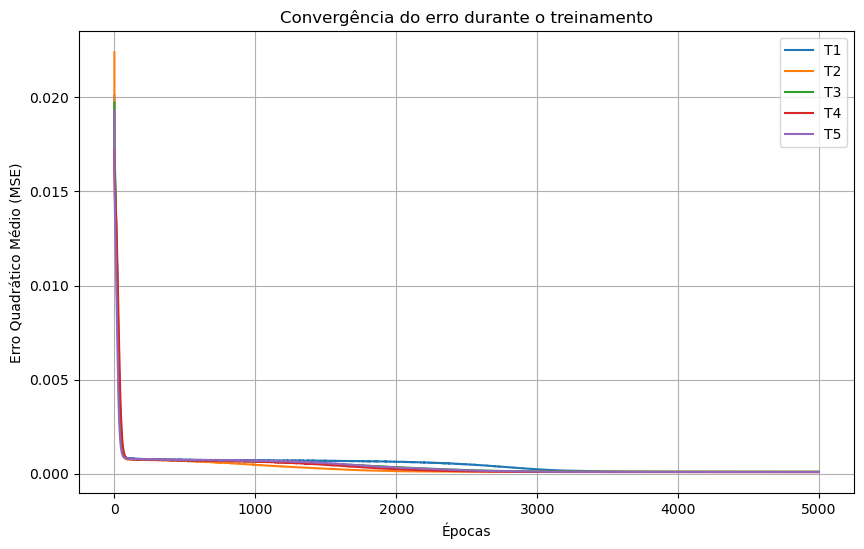

In [18]:
plt.figure(figsize=(10,6))

for i, history in enumerate(histories):
    plt.plot(history, label=f'T{i+1}')

plt.xlabel('Épocas')
plt.ylabel('Erro Quadrático Médio (MSE)')
plt.title('Convergência do erro durante o treinamento')
plt.legend()
plt.grid(True)
plt.show()

## 7. Comparação com Scikit-Learn (MLPRegressor)

Para validar nossa implementação manual, utilizaremos o `MLPRegressor` do scikit-learn com as mesmas configurações de arquitetura e hiperparâmetros.

In [16]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error

print("--- Executando 5 Treinamentos com Scikit-Learn ---")

sk_results = []
sk_models = []
sk_predictions = []

for i in range(5):
    sk_mlp = MLPRegressor(
        hidden_layer_sizes=(10,),
        activation='logistic',
        solver='sgd',
        learning_rate_init=0.1,
        tol=1e-6,
        max_iter=5000,
        random_state=i + 42, # Sementes variadas
        shuffle=True
    )
    sk_mlp.fit(X_train, D_train.ravel())
    sk_models.append(sk_mlp)
    
    Y_pred_sk = sk_mlp.predict(X_test)
    sk_predictions.append(Y_pred_sk)
    
    sk_results.append({
        'Treinamento': f'SK{i+1}',
        'Erro quadrático médio': sk_mlp.loss_,
        'Número total de épocas': sk_mlp.n_iter_
    })

df_res_sk = pd.DataFrame(sk_results)
print("\nTabela 5.4 – Resultados dos treinamentos (Scikit-Learn)")
display(df_res_sk)

# Tabela Detalhada de Validação
df_val_sk_detailed = test_df.copy()
for i, pred in enumerate(sk_predictions):
    df_val_sk_detailed[f'y_SK{i+1}'] = pred

print("\nTabela Detalhada de Amostras e Predições - Scikit-Learn (SK1 a SK5):")
display(df_val_sk_detailed)

# Resumo das Métricas
val_results_sk_summary = []
for i, pred in enumerate(sk_predictions):
    rel_errors = np.abs(D_test - pred) / D_test * 100
    val_results_sk_summary.append({
        'Treinamento': f'SK{i+1}',
        'Erro relativo médio (%)': np.mean(rel_errors),
        'Variância (%)': np.var(rel_errors)
    })

df_val_sk = pd.DataFrame(val_results_sk_summary)
print("\nTabela 5.5 – Resumo das Métricas de Validação (Scikit-Learn):")
display(df_val_sk)

sk_best_error = df_val_sk['Erro relativo médio (%)'].min()

--- Executando 5 Treinamentos com Scikit-Learn ---

Tabela 5.4 – Resultados dos treinamentos (Scikit-Learn)


,Treinamento,Erro quadrático médio,Número total de épocas
0,SK1,0.000616,231
1,SK2,0.000610,275
2,SK3,0.000597,237
3,SK4,0.000602,219
4,SK5,0.000582,244



Tabela Detalhada de Amostras e Predições - Scikit-Learn (SK1 a SK5):


,Amostra,x1,x2,x3,d,y_SK1,y_SK2,y_SK3,y_SK4,y_SK5
0,1,0.0611,0.2860,0.7464,0.4831,0.486429,0.487694,0.496621,0.496365,0.496678
1,2,0.5102,0.7464,0.0860,0.5965,0.591305,0.594628,0.588670,0.582907,0.583776
2,3,0.0004,0.6916,0.5006,0.5318,0.528018,0.531736,0.533641,0.530534,0.531489
3,4,0.9430,0.4476,0.2648,0.6843,0.696077,0.694534,0.690573,0.687924,0.692436
4,5,0.1399,0.1610,0.2477,0.2872,0.303093,0.299117,0.304153,0.305133,0.300118
5,6,0.6423,0.3229,0.8567,0.7663,0.738563,0.739120,0.740481,0.745693,0.747804
6,7,0.6492,0.0007,0.6422,0.5666,0.560064,0.560571,0.563047,0.566304,0.570378
7,8,0.1818,0.5078,0.9046,0.6601,0.657921,0.662859,0.667044,0.668923,0.669348
8,9,0.7382,0.2647,0.1916,0.5427,0.537007,0.537599,0.533724,0.533241,0.536454
9,10,0.3879,0.1307,0.8656,0.5836,0.586277,0.588384,0.594649,0.597704,0.599916



Tabela 5.5 – Resumo das Métricas de Validação (Scikit-Learn):


,Treinamento,Erro relativo médio (%),Variância (%)
0,SK1,1.846794,2.461593
1,SK2,1.657037,1.660448
2,SK3,2.077940,2.669143
3,SK4,2.065289,3.146938
4,SK5,1.937940,1.709319


## 8. Abordagem com Deep Learning (Keras/TensorFlow)

Da mesma forma, podemos aplicar o **Keras** para problemas de regressão. Utilizaremos uma rede com mais neurônios nas camadas ocultas e o otimizador Adam para buscar uma melhor generalização.

A diferença de performance inicial do Keras se deveu principalmente ao uso de **Batch Gradient Descent** (atualização dos pesos apenas uma vez por época) contra o **Stochastic Gradient Descent (Online Learning)** da implementação manual (atualização a cada amostra). Em 5000 épocas, a implementação manual realizou 1.000.000 de atualizações, enquanto o Keras realizou apenas 5.000. Abaixo, otimizamos o Keras com o otimizador **Adam** e um \`batch_size\` menor para mostrar seu verdadeiro potencial.

In [17]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

print("--- Executando 5 Treinamentos com Keras ---")

keras_results = []
keras_models = []
keras_predictions = []

for i in range(5):
    # Definindo o modelo Keras para Regressão conforme especificações do projeto
    model_keras = Sequential([
        Dense(10, activation='sigmoid', input_shape=(3,)),
        Dense(1, activation='sigmoid')
    ])

    model_keras.compile(
        optimizer=Adam(learning_rate=0.01),
        loss='mse'
    )

    # Treinamento
    history_keras = model_keras.fit(
        X_train, D_train, 
        epochs=5000, 
        batch_size=16, # Batch size reduzido para melhor convergência
        verbose=0
    )

    keras_models.append(model_keras)

    Y_pred_keras = model_keras.predict(X_test, verbose=0)
    keras_predictions.append(Y_pred_keras.ravel())

    keras_results.append({
        'Treinamento': f'K{i+1}',
        'Erro quadrático médio': history_keras.history['loss'][-1],
        'Número total de épocas': len(history_keras.history['loss'])
    })

df_res_keras = pd.DataFrame(keras_results)
print("\nTabela 5.6 – Resultados dos treinamentos (Keras)")
display(df_res_keras)

# Tabela Detalhada de Validação
df_val_keras_detailed = test_df.copy()
for i, pred in enumerate(keras_predictions):
    df_val_keras_detailed[f'y_K{i+1}'] = pred

print("\nTabela Detalhada de Amostras e Predições - Keras (K1 a K5):")
display(df_val_keras_detailed)

# Resumo das Métricas
val_results_keras_summary = []
for i, pred in enumerate(keras_predictions):
    rel_errors = np.abs(D_test - pred) / D_test * 100
    val_results_keras_summary.append({
        'Treinamento': f'K{i+1}',
        'Erro relativo médio (%)': np.mean(rel_errors),
        'Variância (%)': np.var(rel_errors)
    })

df_val_keras = pd.DataFrame(val_results_keras_summary)
print("\nTabela 5.7 – Resumo das Métricas de Validação (Keras):")
display(df_val_keras)

# Comparação Tripla Final
manual_best_error = df_val['Erro relativo médio (%)'].min()
sk_best_error = df_val_sk['Erro relativo médio (%)'].min()
keras_best_error = df_val_keras['Erro relativo médio (%)'].min()

print("\n--- Comparação Tripla (Melhores Resultados) ---")
print(f"Melhor Erro Manual: {manual_best_error:.4f}%")
print(f"Melhor Erro Scikit-Learn: {sk_best_error:.4f}%")
print(f"Melhor Erro Keras: {keras_best_error:.4f}%")

--- Executando 5 Treinamentos com Keras ---


/home/enzosarmento/anaconda3/envs/Titanic/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Tabela 5.6 – Resultados dos treinamentos (Keras)


,Treinamento,Erro quadrático médio,Número total de épocas
0,K1,0.000011,5000
1,K2,0.000020,5000
2,K3,0.000023,5000
3,K4,0.000040,5000
4,K5,0.000020,5000



Tabela Detalhada de Amostras e Predições - Keras (K1 a K5):


,Amostra,x1,x2,x3,d,y_K1,y_K2,y_K3,y_K4,y_K5
0,1,0.0611,0.2860,0.7464,0.4831,0.485189,0.482647,0.484699,0.481523,0.477738
1,2,0.5102,0.7464,0.0860,0.5965,0.597756,0.593613,0.592409,0.582153,0.590430
2,3,0.0004,0.6916,0.5006,0.5318,0.535926,0.537184,0.529466,0.519681,0.535916
3,4,0.9430,0.4476,0.2648,0.6843,0.680563,0.679908,0.684041,0.678738,0.677175
4,5,0.1399,0.1610,0.2477,0.2872,0.282384,0.281631,0.279600,0.273586,0.279234
5,6,0.6423,0.3229,0.8567,0.7663,0.764315,0.764163,0.766133,0.758930,0.761188
6,7,0.6492,0.0007,0.6422,0.5666,0.565633,0.565913,0.565038,0.560037,0.559839
7,8,0.1818,0.5078,0.9046,0.6601,0.657514,0.657773,0.655777,0.650636,0.652098
8,9,0.7382,0.2647,0.1916,0.5427,0.540353,0.537155,0.536069,0.531466,0.537068
9,10,0.3879,0.1307,0.8656,0.5836,0.583992,0.580385,0.579891,0.572392,0.574927



Tabela 5.7 – Resumo das Métricas de Validação (Keras):


,Treinamento,Erro relativo médio (%),Variância (%)
0,K1,0.518437,0.172916
1,K2,0.673059,0.180194
2,K3,0.643176,0.317207
3,K4,1.545942,0.977460
4,K5,1.103757,0.440178



--- Comparação Tripla (Melhores Resultados) ---
Melhor Erro Manual: 1.5942%
Melhor Erro Scikit-Learn: 1.6570%
Melhor Erro Keras: 0.5184%
